In [1]:
.root <- getwd()
while (!file.exists(file.path(.root, 'CLAUDE.md')) && dirname(.root) != .root)
  .root <- dirname(.root)
setwd(.root)
rm(.root)

suppressPackageStartupMessages({
  library(tidyverse)
  library(ggthemes)
  library(ggrepel)
  library(scales)
  library(patchwork)
})

options(repr.plot.width = 14, repr.plot.height = 8)

BASE_THEME <- theme_fivethirtyeight() +
  theme(
    axis.title        = element_text(size = 14),
    axis.text         = element_text(size = 13),
    panel.background  = element_rect(fill = 'white', color = NA),
    plot.background   = element_rect(fill = 'white', color = NA),
    legend.background = element_rect(fill = 'white', color = NA),
    legend.text       = element_text(size = 12),
    legend.title      = element_text(size = 13),
    strip.text        = element_text(size = 14, face = 'bold'),
    plot.title        = element_text(size = 20, face = 'bold'),
    plot.subtitle     = element_text(size = 13)
  )
theme_set(BASE_THEME)

PITCH_NAMES <- c(
  FF = '4-Seam', SI = 'Sinker', FC = 'Cutter',
  CH = 'Changeup', FS = 'Splitter',
  SL = 'Slider', CU = 'Curveball', ST = 'Sweeper', KC = 'Knuckle-curve'
)
PITCH_COLORS <- c(
  FF = '#d62728', SI = '#ff7f0e', FC = '#e377c2',
  CH = '#2ca02c', FS = '#17becf',
  SL = '#bcbd22', CU = '#1f77b4', ST = '#9467bd', KC = '#8c564b'
)

dir.create('results/plots/applications', recursive = TRUE, showWarnings = FALSE)

Warning message:
"il pacchetto 'dplyr' `e stato creato con R versione 4.4.3"


In [2]:
seq_df    <- read_csv('data/viz_cache/app_sequencing.csv',           show_col_types = FALSE)
batter    <- read_csv('data/viz_cache/app_batter_vulnerability.csv', show_col_types = FALSE)
batter_pt <- read_csv('data/viz_cache/app_batter_by_pitch_type.csv', show_col_types = FALSE)
pitch_adj <- read_csv('data/viz_cache/app_pitcher_adjusted.csv',     show_col_types = FALSE)
pitch_ols <- read_csv('data/viz_cache/app_pitcher_ols.csv',          show_col_types = FALSE)
tr_wfall  <- read_csv('data/viz_cache/app_tyler_rogers_waterfall.csv', show_col_types = FALSE)

cat(sprintf(
  'Loaded | seq pairs: %d | batters: %d | pitchers: %d | ols: %d\n',
  nrow(seq_df), nrow(batter), nrow(pitch_adj), nrow(pitch_ols)
))


Loaded | seq pairs: 79 | batters: 542 | pitchers: 509 | ols: 509


## Pitch Sequencing Value

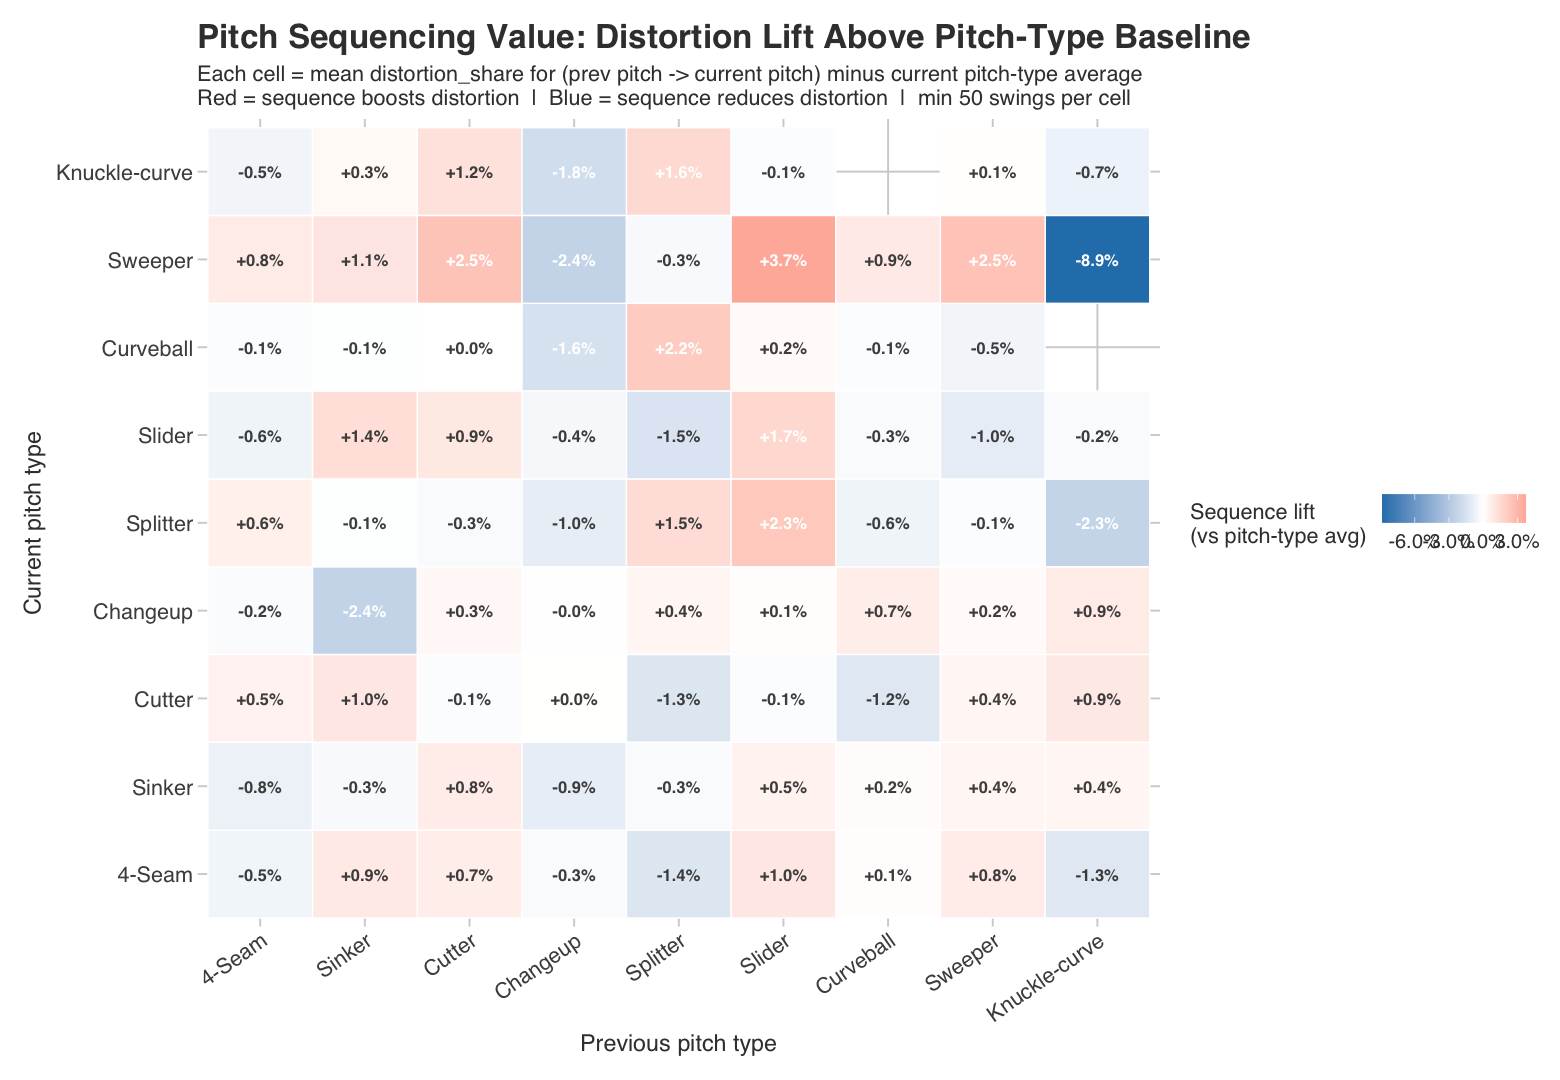

In [3]:
PITCH_ORDER <- c('4-Seam','Sinker','Cutter','Changeup','Splitter',
                 'Slider','Curveball','Sweeper','Knuckle-curve')

# Compute baseline distortion per current pitch type
baseline_by_type <- seq_df |>
  group_by(pitch_name) |>
  summarise(baseline = mean(mean_distortion_share), .groups = 'drop')

seq_lift <- seq_df |>
  left_join(baseline_by_type, by = 'pitch_name') |>
  mutate(
    seq_lift      = mean_distortion_share - baseline,
    prev_pitch_name = factor(prev_pitch_name, levels = PITCH_ORDER),
    pitch_name      = factor(pitch_name,      levels = PITCH_ORDER)
  )

p_heatmap <- ggplot(seq_lift,
                    aes(x = prev_pitch_name, y = pitch_name,
                        fill = seq_lift)) +
  geom_tile(color = 'white', linewidth = 0.4) +
  geom_text(
    aes(label = sprintf('%+.1f%%', seq_lift * 100)),
    size = 3.5, fontface = 'bold',
    color = ifelse(abs(seq_lift$seq_lift) > 0.015, 'white', 'grey30')
  ) +
  scale_fill_gradient2(
    low  = '#2980b9', mid = 'white', high = '#e74c3c',
    midpoint = 0,
    labels = percent_format(accuracy = 0.1),
    name = 'Sequence lift\n(vs pitch-type avg)'
  ) +
  labs(
    title    = 'Pitch Sequencing Value: Distortion Lift Above Pitch-Type Baseline',
    subtitle = paste0(
      'Each cell = mean distortion_share for (prev pitch -> current pitch) minus current pitch-type average\n',
      'Red = sequence boosts distortion  |  Blue = sequence reduces distortion  |  min 50 swings per cell'
    ),
    x = 'Previous pitch type',
    y = 'Current pitch type'
  ) +
  theme(
    axis.text.x    = element_text(angle = 35, hjust = 1),
    legend.position = 'right'
  )

options(repr.plot.width = 13, repr.plot.height = 9)
p_heatmap
ggsave('results/plots/applications/sequencing_heatmap.png', p_heatmap,
       width = 13, height = 9, dpi = 150)

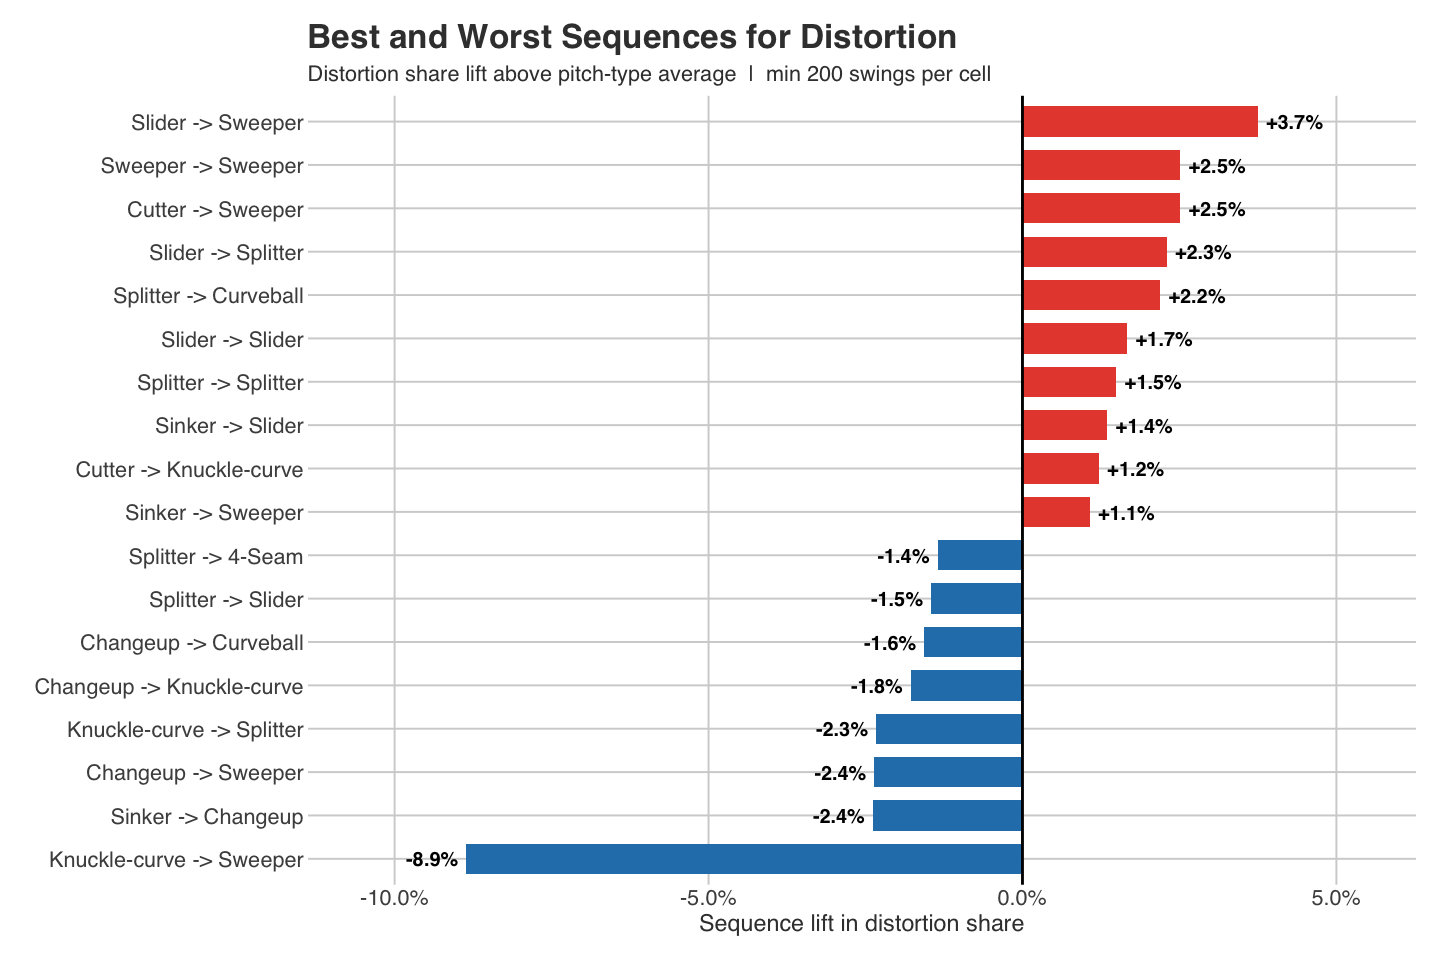

In [4]:
top_seqs <- seq_lift |>
  filter(n >= 200) |>
  mutate(label = paste(prev_pitch_name, '->', pitch_name)) |>
  arrange(desc(seq_lift)) |>
  slice(c(1:10, (n() - 7):n()))

p_top <- ggplot(top_seqs,
                aes(x = reorder(label, seq_lift),
                    y = seq_lift,
                    fill = seq_lift > 0)) +
  geom_col(width = 0.7) +
  geom_hline(yintercept = 0, linewidth = 0.8) +
  geom_text(
    aes(label = sprintf('%+.1f%%', seq_lift * 100),
        hjust = ifelse(seq_lift > 0, -0.15, 1.15)),
    size = 4.2, fontface = 'bold'
  ) +
  scale_fill_manual(values = c('FALSE' = '#2980b9', 'TRUE' = '#e74c3c'), guide = 'none') +
  scale_y_continuous(labels = percent_format(accuracy = 0.1),
                     expand = expansion(mult = c(0.2, 0.2))) +
  coord_flip() +
  labs(
    title    = 'Best and Worst Sequences for Distortion',
    subtitle = 'Distortion share lift above pitch-type average  |  min 200 swings per cell',
    x = NULL, y = 'Sequence lift in distortion share'
  )

options(repr.plot.width = 12, repr.plot.height = 8)
p_top
ggsave('results/plots/applications/sequencing_top.png', p_top,
       width = 12, height = 8, dpi = 150)

## Batter Vulnerability

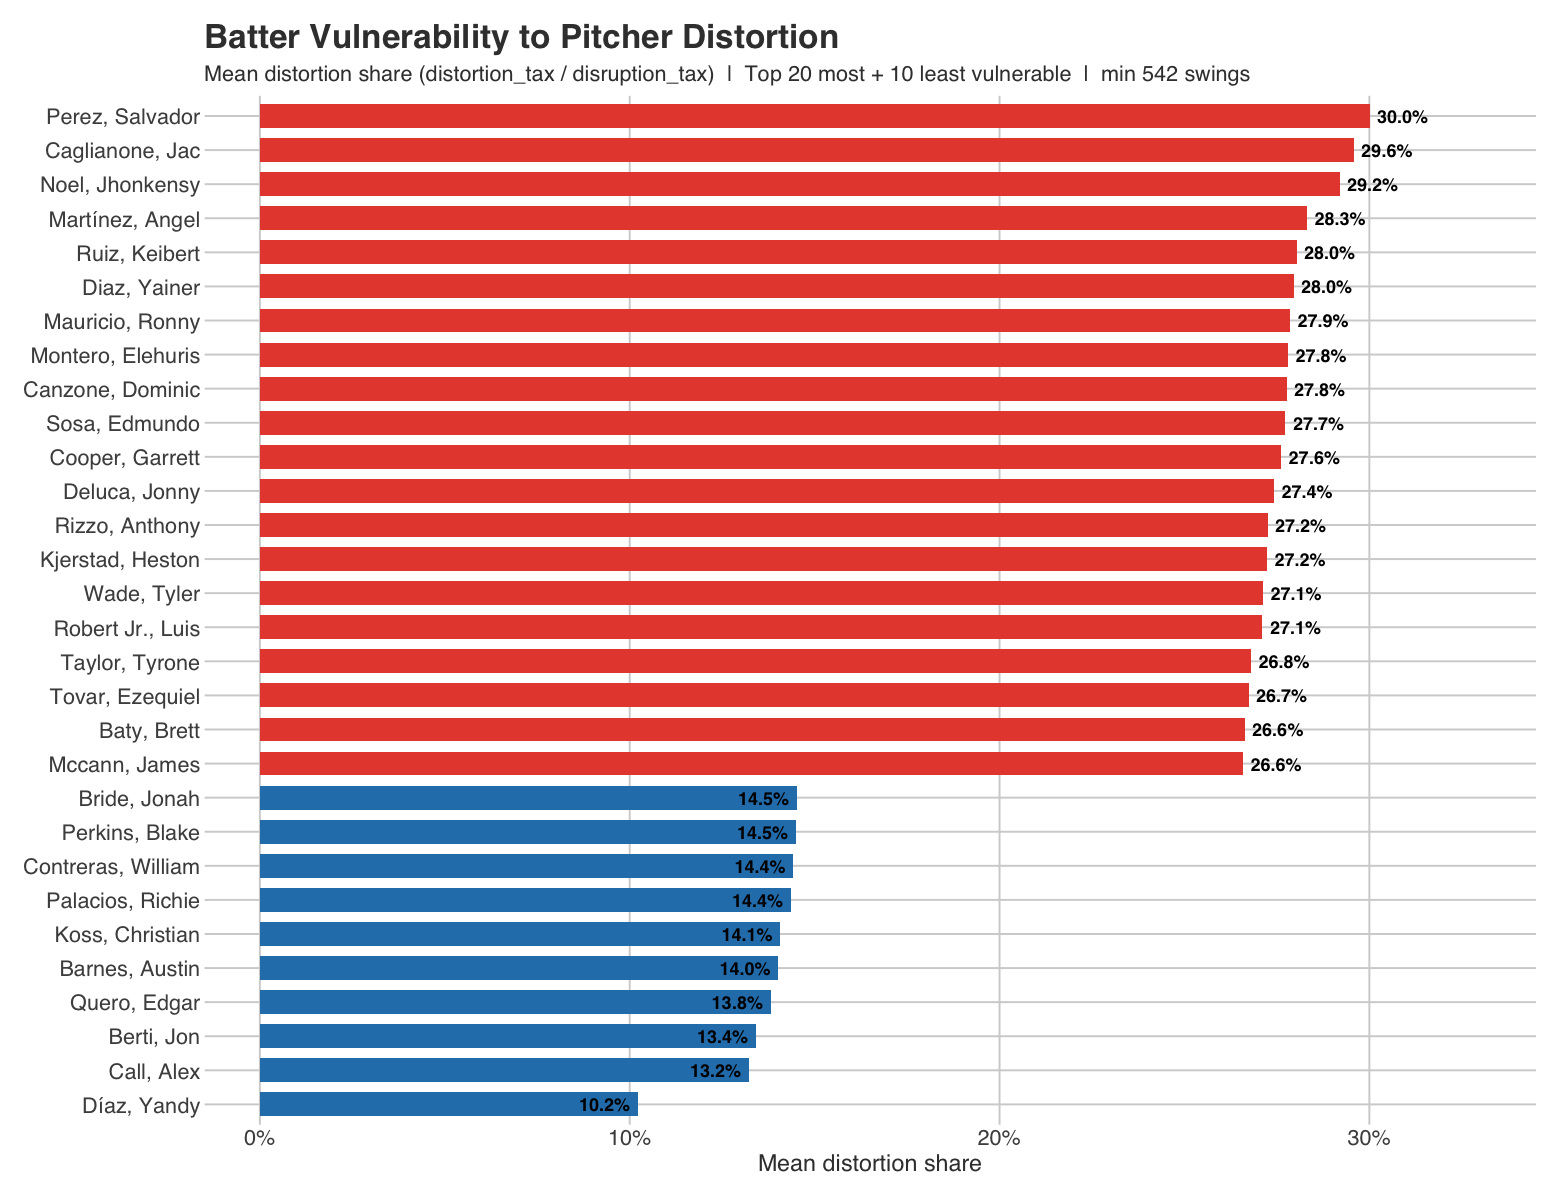

In [5]:
top_bottom_batters <- bind_rows(
  batter |> arrange(desc(mean_distortion_share)) |> slice(1:20),
  batter |> arrange(mean_distortion_share)       |> slice(1:10)
) |>
  mutate(
    batter_full_name = str_to_title(batter_full_name),
    is_vulnerable    = mean_distortion_share > median(batter$mean_distortion_share)
  )

p_batter <- ggplot(top_bottom_batters,
                   aes(x = reorder(batter_full_name, mean_distortion_share),
                       y = mean_distortion_share,
                       fill = is_vulnerable)) +
  geom_col(width = 0.7) +
  geom_text(
    aes(label = sprintf('%.1f%%', mean_distortion_share * 100),
        hjust = ifelse(is_vulnerable, -0.15, 1.15)),
    size = 3.8, fontface = 'bold'
  ) +
  scale_fill_manual(values = c('FALSE' = '#2980b9', 'TRUE' = '#e74c3c'), guide = 'none') +
  scale_y_continuous(labels = percent_format(accuracy = 1),
                     expand = expansion(mult = c(0.05, 0.15))) +
  coord_flip() +
  labs(
    title    = 'Batter Vulnerability to Pitcher Distortion',
    subtitle = sprintf(
      'Mean distortion share (distortion_tax / disruption_tax)  |  Top 20 most + 10 least vulnerable  |  min %d swings',
      542L
    ),
    x = NULL, y = 'Mean distortion share'
  )

options(repr.plot.width = 13, repr.plot.height = 10)
p_batter
ggsave('results/plots/applications/batter_vulnerability_overall.png', p_batter,
       width = 13, height = 10, dpi = 150)

In [6]:
PITCH_COLORS_NAME <- c(
  'Sweeper' = '#9467bd', 'Curveball' = '#1f77b4',
  'Changeup' = '#2ca02c', 'Slider' = '#bcbd22'
)

batter_top <- batter_pt |>
  filter(pitch_name %in% c('Sweeper', 'Curveball', 'Changeup', 'Slider')) |>
  mutate(
    batter_full_name = str_to_title(batter_full_name),
    pitch_name = factor(pitch_name, levels = c('Sweeper', 'Curveball', 'Changeup', 'Slider'))
  ) |>
  group_by(pitch_name) |>
  arrange(desc(mean_distortion_share)) |>
  slice(1:8) |>
  ungroup()

p_bytype <- ggplot(batter_top,
                   aes(x = reorder(batter_full_name, mean_distortion_share),
                       y = mean_distortion_share,
                       fill = pitch_name)) +
  geom_col(width = 0.7) +
  scale_fill_manual(values = PITCH_COLORS_NAME, guide = 'none') +
  scale_y_continuous(labels = percent_format(accuracy = 1),
                     expand = expansion(mult = c(0.02, 0.15))) +
  facet_wrap(~ pitch_name, scales = 'free_y', ncol = 2) +
  coord_flip() +
  labs(
    title    = 'Batter Vulnerability by Pitch Type',
    subtitle = 'Top 8 most distortion-vulnerable batters for each of the four high-movement pitch types  |  min 50 swings',
    x = NULL, y = 'Mean distortion share'
  )

options(repr.plot.width = 14, repr.plot.height = 10)
p_bytype
ggsave('results/plots/applications/batter_vulnerability_by_pitch_type.png', p_bytype,
       width = 14, height = 10, dpi = 150)


ERROR: [1m[33mError[39m in `filter()`:[22m
[1m[22m[36mi[39m In argument: `pitch_type %in% c("ST", "CU", "CH", "SL")`.
[1mCaused by error:[22m
[33m![39m oggetto 'pitch_type' non trovato


## Pitch-Mix-Adjusted Distortion Leaderboard

In [ ]:
PITCH_ORDER2 <- c('4-Seam','Sinker','Cutter','Changeup','Splitter',
                  'Slider','Curveball','Sweeper','Knuckle-curve')

top_adj <- bind_rows(
  pitch_adj |> arrange(desc(adjusted_distortion_share)) |> slice(1:20),
  pitch_adj |> arrange(adjusted_distortion_share)       |> slice(1:10)
) |>
  mutate(
    pitcher_full_name = str_to_title(pitcher_full_name),
    dominant_name     = coalesce(dominant_name, 'Other'),
    is_above          = adjusted_distortion_share > 0
  )

p_adj <- ggplot(top_adj,
               aes(x = reorder(pitcher_full_name, adjusted_distortion_share),
                   y = adjusted_distortion_share,
                   fill = dominant_name)) +
  geom_col(width = 0.7) +
  geom_hline(yintercept = 0, linewidth = 0.8) +
  geom_text(
    aes(label = sprintf('%+.1f%%', adjusted_distortion_share * 100),
        hjust = ifelse(is_above, -0.15, 1.15)),
    size = 3.5, fontface = 'bold'
  ) +
  scale_fill_manual(
    values = c(
      '4-Seam'='#d62728','Sinker'='#ff7f0e','Cutter'='#e377c2',
      'Changeup'='#2ca02c','Splitter'='#17becf','Slider'='#bcbd22',
      'Curveball'='#1f77b4','Sweeper'='#9467bd','Knuckle-curve'='#8c564b','Other'='#aec7e8'
    ),
    name   = 'Dominant pitch'
  ) +
  scale_y_continuous(labels = percent_format(accuracy = 0.1),
                     expand = expansion(mult = c(0.1, 0.18))) +
  coord_flip() +
  labs(
    title    = 'Pitch-Mix-Adjusted Distortion: Who Distorts Above Their Arsenal?',
    subtitle = paste0(
      'Adjusted distortion share = actual minus expected given pitch mix  |  ',
      'Top 20 above + 10 below expected  |  min 500 swings\n',
      'Positive = pitcher generates more distortion than their pitch types typically would'
    ),
    x = NULL, y = 'Adjusted distortion share (actual - expected)'
  ) +
  theme(legend.position = 'right')

options(repr.plot.width = 14, repr.plot.height = 10)
p_adj
ggsave('results/plots/applications/pitcher_adjusted_leaderboard.png', p_adj,
       width = 14, height = 10, dpi = 150)


## Pitcher Mechanics vs Disruption Tax

In [ ]:
r_ht  <- cor(pitch_ols$mean_release_pos_z, pitch_ols$mean_disruption, use = 'complete.obs')
r_arm <- cor(pitch_ols$mean_arm_angle,     pitch_ols$mean_disruption, use = 'complete.obs')

label_df2 <- bind_rows(
  pitch_ols |> arrange(mean_disruption)         |> slice(1:8),
  pitch_ols |> arrange(desc(mean_disruption))   |> slice(1:5)
) |>
  mutate(pitcher_full_name = str_to_title(pitcher_full_name))

p_ols <- ggplot(pitch_ols,
                aes(x = mean_release_pos_z, y = mean_disruption)) +
  geom_point(aes(size = n_swings, color = mean_arm_angle), alpha = 0.65) +
  geom_smooth(method = 'lm', se = TRUE, color = '#e74c3c',
              linewidth = 1.0, fill = '#e74c3c', alpha = 0.1) +
  geom_text_repel(
    data    = label_df2,
    mapping = aes(label = pitcher_full_name),
    size    = 3.3, max.overlaps = 15, segment.color = 'grey60'
  ) +
  scale_color_gradient(low = '#e74c3c', high = '#2980b9',
                       name = 'Arm angle (deg)') +
  scale_size_continuous(range = c(2, 7), guide = 'none') +
  scale_y_continuous(labels = function(x) sprintf('%.3f', x)) +
  annotate('text', x = Inf, y = Inf, hjust = 1.1, vjust = 1.8,
           label = sprintf('r = %.2f | n = %d pitchers', r_ht, nrow(pitch_ols)),
           size = 4.5, fontface = 'bold', color = '#c0392b') +
  labs(
    title    = 'Lower Release Height -> More Disruption',
    subtitle = paste0(
      'Mean disruption tax vs release height (arm angle proxy)  |  min 500 swings\n',
      'Color = arm angle (red = sidearm, blue = over-the-top)  |  Size = swings faced'
    ),
    x = 'Mean release height (ft)',
    y = 'Mean disruption tax (runs/swing)'
  )

options(repr.plot.width = 13, repr.plot.height = 8)
p_ols
ggsave('results/plots/applications/pitcher_mechanics_ols.png', p_ols,
       width = 13, height = 8, dpi = 150)


## Tyler Rogers: Mechanical Decomposition of Disruption Value

In [ ]:
tr_wfall <- tr_wfall |>
  mutate(
    component = factor(component, levels = component),
    color_group = case_when(
      type == 'baseline'  ~ 'Baseline',
      type == 'residual'  ~ 'Unexplained',
      value < 0           ~ 'Increases disruption',
      TRUE                ~ 'Reduces disruption'
    )
  )

actual_val <- tr_wfall$cumulative_end[nrow(tr_wfall)]

p_wfall <- ggplot(tr_wfall,
                  aes(x = component,
                      ymin = cumulative_start, ymax = cumulative_end,
                      fill = color_group)) +
  geom_rect(aes(xmin = as.numeric(component) - 0.4,
                xmax = as.numeric(component) + 0.4,
                ymin = cumulative_start,
                ymax = cumulative_end),
            color = 'white', linewidth = 0.4) +
  geom_hline(yintercept = actual_val, linetype = 'dashed',
             color = 'grey40', linewidth = 0.8) +
  geom_text(
    aes(y = (cumulative_start + cumulative_end) / 2,
        label = sprintf('%+.4f', value)),
    size = 4, fontface = 'bold', color = 'white'
  ) +
  annotate('text', x = nrow(tr_wfall) + 0.1, y = actual_val + 0.0015,
           label = sprintf('Actual: %.4f', actual_val),
           hjust = 1, size = 4, color = 'grey30') +
  scale_fill_manual(
    values = c(
      'Baseline'              = '#7f8c8d',
      'Increases disruption'  = '#e74c3c',
      'Reduces disruption'    = '#2980b9',
      'Unexplained'           = '#8e44ad'
    ),
    name = NULL
  ) +
  scale_y_continuous(labels = function(x) sprintf('%.3f', x)) +
  labs(
    title    = 'Tyler Rogers: What Makes Him So Disruptive?',
    subtitle = paste0(
      'OLS decomposition of disruption tax (runs/swing)  |  Starting from league average\n',
      'Red bars push disruption higher; blue bars reduce it  |  OLS R\u00b2 = 0.472 across 509 pitchers'
    ),
    x = NULL, y = 'Disruption tax (runs/swing)'
  ) +
  theme(legend.position = 'top',
        axis.text.x = element_text(angle = 15, hjust = 1))

options(repr.plot.width = 12, repr.plot.height = 7)
p_wfall
ggsave('results/plots/applications/tyler_rogers_waterfall.png', p_wfall,
       width = 12, height = 7, dpi = 150)
